# **Mini Projet : Analyse en Composantes Principales (ACP)**



# **0. Saisie des données**



In [ ]:
!pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"Body Measurements.csv")
df = df.iloc[:, 1:]

# Keep only numeric columns for PCA
df = df.dropna()
df = df.reset_index(drop=True)
df.index = [f'S{i+1}' for i in range(len(df))]


# #affichage
# df.style.set_properties(**{
#     'text-align': 'center',
#     'border': '1px solid black',
#     'padding': '6px'
# }).set_table_styles([
#     {'selector': 'caption',
#      'props': [
#          ('font-size', '20px'),
#          ('font-weight', 'bold'),
#          ('color', '#2c3e50'),
#          ('text-align', 'center'),
#          ('padding', '10px')
#      ]}
# ]).set_caption("DATASET ")

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
import numpy as np
import pandas as pd


# **1. Standardisation**





La standardisation consiste à transformer les données pour que chaque variable ait :
- une moyenne égale à 0  
- un écart-type égal à 1  

Cette étape permet de mettre toutes les variables sur la même échelle, afin qu’elles contribuent équitablement à l’analyse.



### Moyenne (mean)

$$
\bar{x} = \frac{1}{n} \sum x_i
$$



### Écart-type (standard deviation)

Il mesure la dispersion des valeurs autour de la moyenne.
$$
\sigma = \sqrt{\frac{1}{n}\sum (x_i - \bar{x})^2}
$$

### Variable standardisée

Chaque valeur est transformée par la formule :

$$
z = \frac{x - \text{moyenne}}{\text{écart-type}}
$$

In [118]:
# Mean = sum of the values ÷ number of individuals
mean_col = {}
n = df.shape[0]  # 15

for col in df.columns:
    mean_col[col] = df[col].sum() / n

# Standard deviation = square root of the mean of the squared deviations
std_col = {}
for col in df.columns:
    sq_diff = [(x - mean_col[col])**2 for x in df[col]]
    std_col[col] = (sum(sq_diff)/n)**0.5 # racine


#mean_col = df.mean()
# Écart-type pour  test
#std_col = df.std(ddof=0)

In [119]:
Z = pd.DataFrame(index=df.index, columns=df.columns)

for col in df.columns:
    Z[col] = [(x - mean_col[col]) / std_col[col] for x in df[col]]



Z = Z.round(2)
# affichage
# Z.style.format("{:.2f}").set_properties(**{
#     'text-align': 'center',
#     'border': '1px solid black',
#     'padding': '6px'
# }).set_table_styles([
#     {'selector': 'caption',
#      'props': [
#          ('font-size', '20px'),
#          ('font-weight', 'bold'),
#          ('color', '#2c3e50'),
#          ('text-align', 'center'),
#          ('padding', '10px')
#      ]}
# ]).set_caption("DATASET STANDARDISÉ")

# **2. The correlation matrix.**
$$R = \frac{1}{n} Z^T Z$$

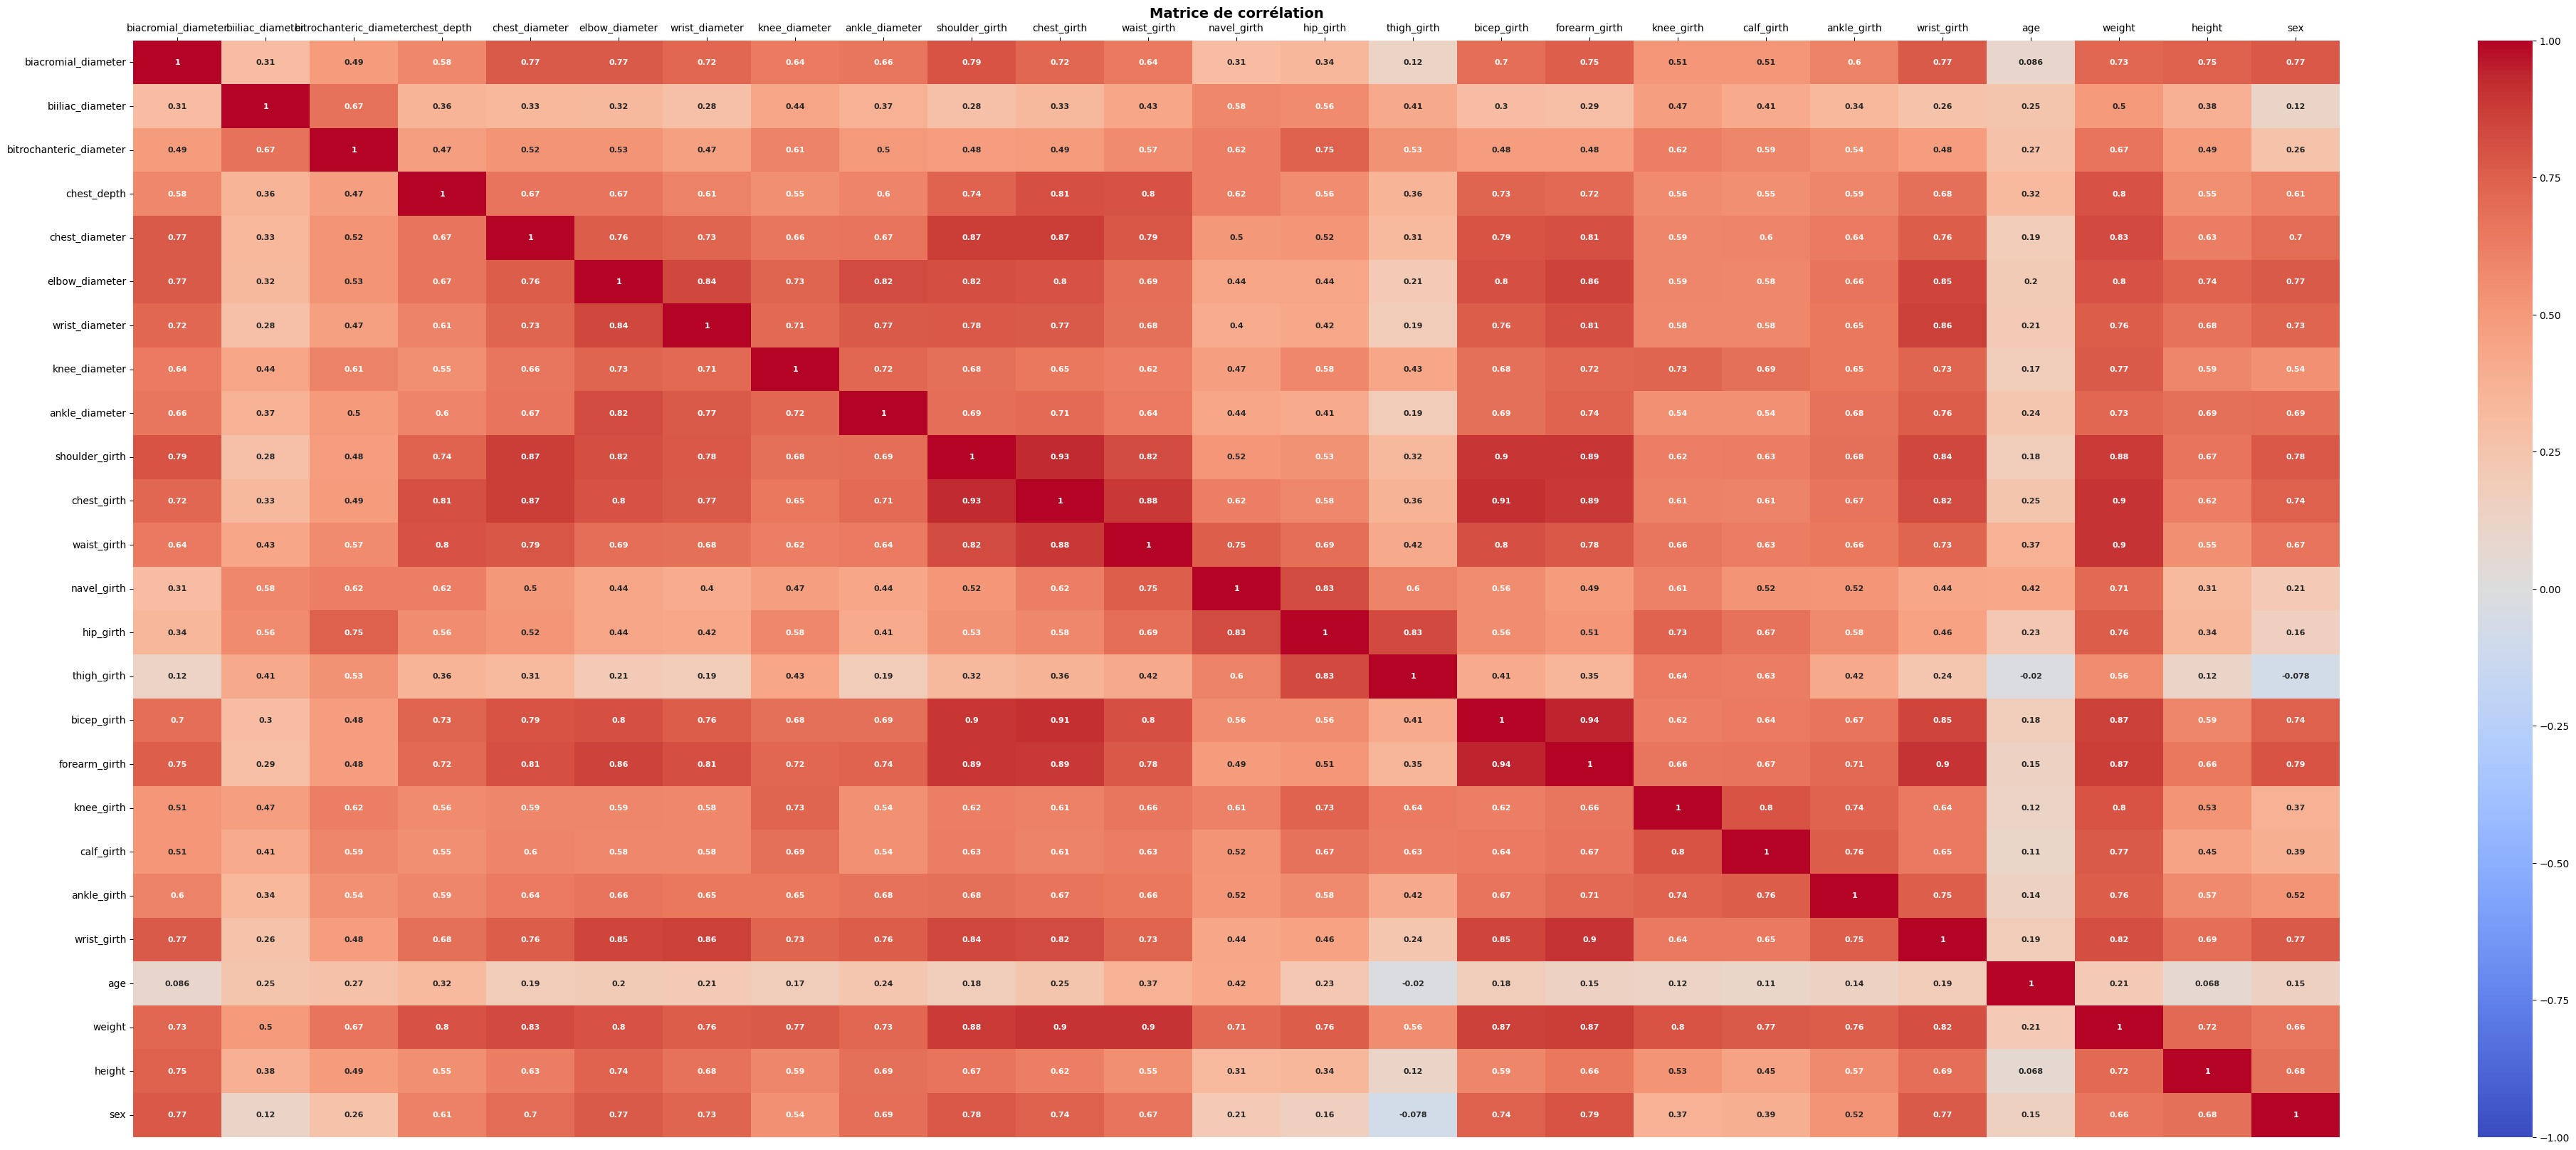

In [121]:

# Number of individuals
n = Z.shape[0]

# Correlation Matrix Calculation
R = np.dot(Z.T, Z) / n
R.round(2)
# ou par fonction prédéfini
corr_matrix = df.corr()

plt.figure(figsize=(50,20))
annot_kws = {'fontsize': 8, 'fontweight': 'bold'}
ax = sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, cmap="coolwarm" ,annot_kws=annot_kws)
plt.title("Matrice de corrélation",fontsize=14, fontweight='bold')
ax.xaxis.tick_top()
plt.show()



# **3. Les valeurs propres, le pourcentage d’inertie et le pourcentage cumulé**



##  **1. Les valeurs propres (Eigenvalues)**

* Les valeurs propres proviennent de la matrice de covariance ou de corrélation.
* Elles mesurent la quantité d’information (variance) capturée par chaque axe principal.


##  **2. Pourcentage d’inertie (Inertia (Variance))**

* L’inertie correspond à la part de variance expliquée par chaque composante.

$$
\text{Inertie}_i = \frac{\lambda_i}{\sum_{j=1}^{p} \lambda_j} \times 100
$$


## **3. Pourcentage cumulé**

* Le pourcentage cumulé additionne progressivement les inerties.

$$
\text{Cumul}_k = \sum_{i=1}^{k} \text{Inertie}_i
$$

* Il permet de savoir combien d’information est conservée en gardant k axes.



In [122]:
eigvals, eigvecs = np.linalg.eig(corr_matrix)

# Trier les valeurs propres
idx = np.argsort(eigvals)[::-1]


# Pourcentage d’inertie
total = 0
for val in eigvals:
    total += val

percent_inertia = []
for val in eigvals:
    percent = (val / total) * 100
    percent_inertia.append(round(percent, 2))

# Pourcentage cumulé
cumulative_percent = []
cum_sum = 0
for val in percent_inertia:
    cum_sum += val
    cumulative_percent.append(round(cum_sum, 2))

# affichage
result = pd.DataFrame({
    "Eigenvalue": eigvals,
    "Inertia (%)": percent_inertia,
    "Cumulative (%)": cumulative_percent
}, index=[f"PC{i+1}" for i in range(len(eigvals))])
result.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '6px'
}).format("{:.2f}")

,Eigenvalue,Inertia (%),Cumulative (%)
PC1,15.52,62.09,62.09
PC2,2.82,11.26,73.35
PC3,1.30,5.20,78.55
PC4,1.06,4.25,82.80
PC5,0.71,2.83,85.63
PC6,0.44,1.75,87.38
PC7,0.40,1.62,89.00
PC8,0.33,1.31,90.31
PC9,0.31,1.24,91.55
PC10,0.27,1.10,92.65


# **3.1. Représentation des valeurs propres (Histogramme).**

TypeError: 'DataFrame' object is not callable

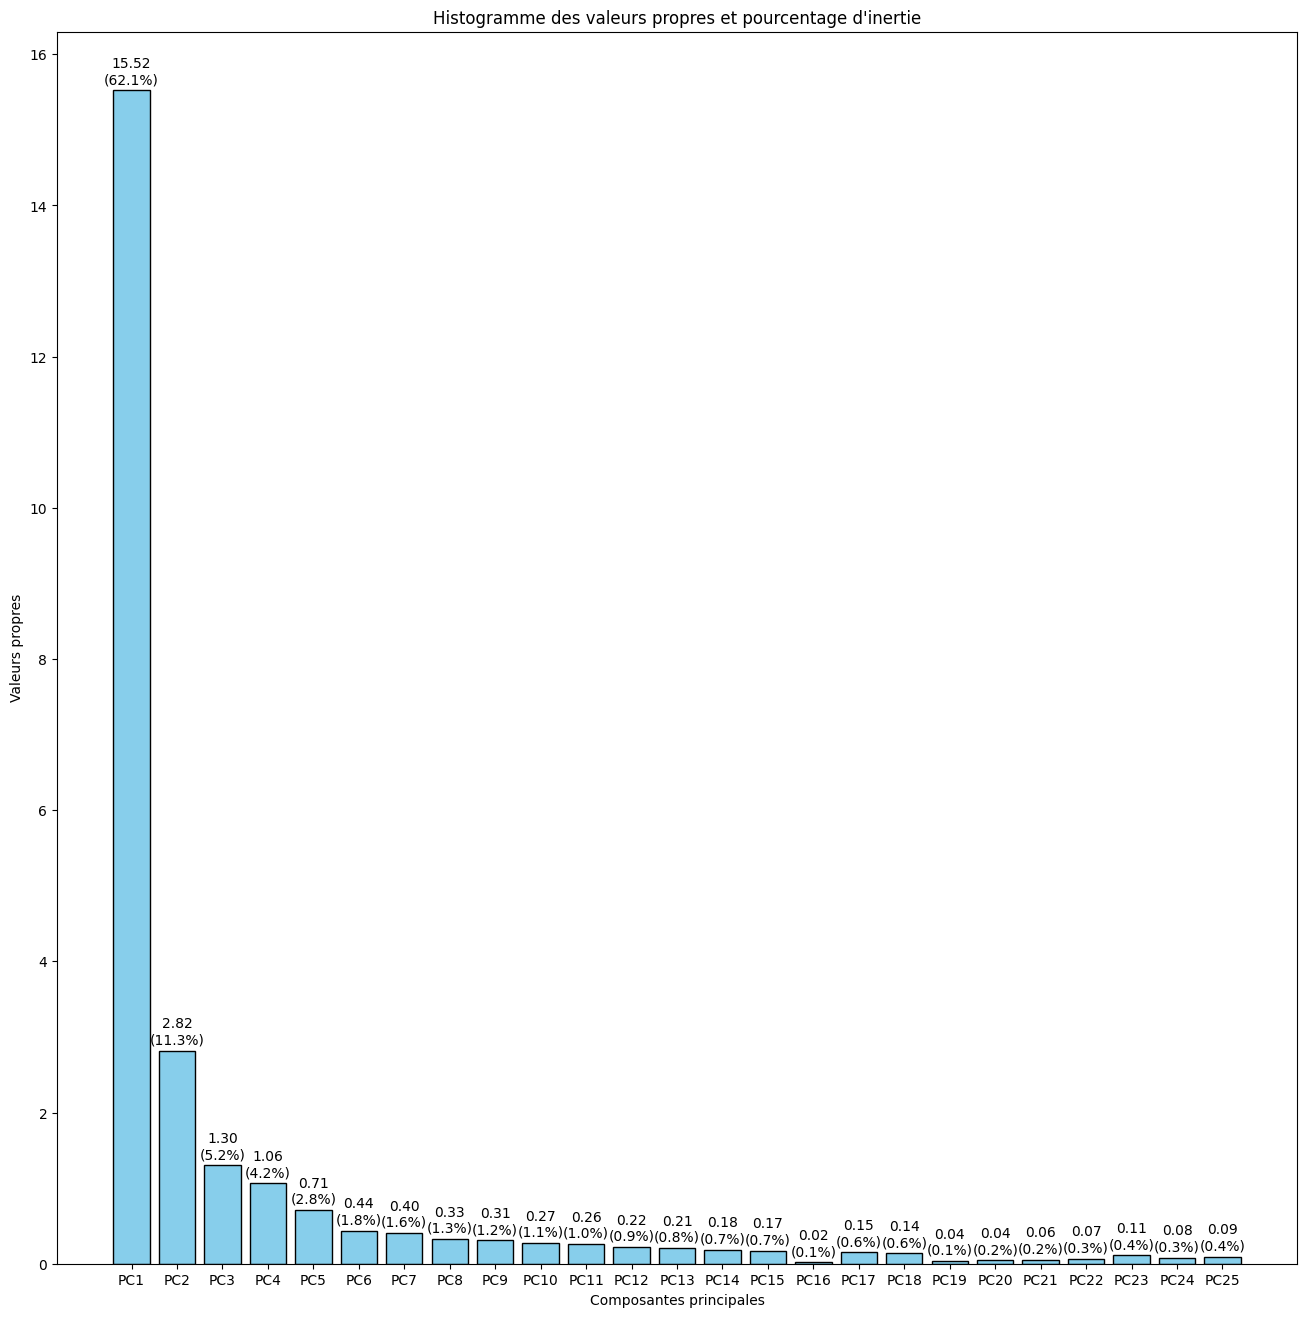

In [123]:

import matplotlib.pyplot as plt

pcs = [f"PC{i+1}" for i in range(len(eigvals))]


plt.figure(figsize=(16,16))

# Histogramme
plt.bar(pcs, eigvals, color='skyblue', edgecolor='black')

# Affichage valeurs propres + %
for i in range(len(eigvals)):
    plt.text(i, eigvals[i] + 0.05,
             f"{eigvals[i]:.2f}\n({percent_inertia[i]:.1f}%)",
             ha='center', va='bottom')

# Titres
plt.title("Histogramme des valeurs propres et pourcentage d'inertie")
plt.xlabel("Composantes principales")
plt.ylabel("Valeurs propres")

plt.ylim(0, max(eigvals)*1.3)

plt.show()

# **3.2. Histogramme du cumul**

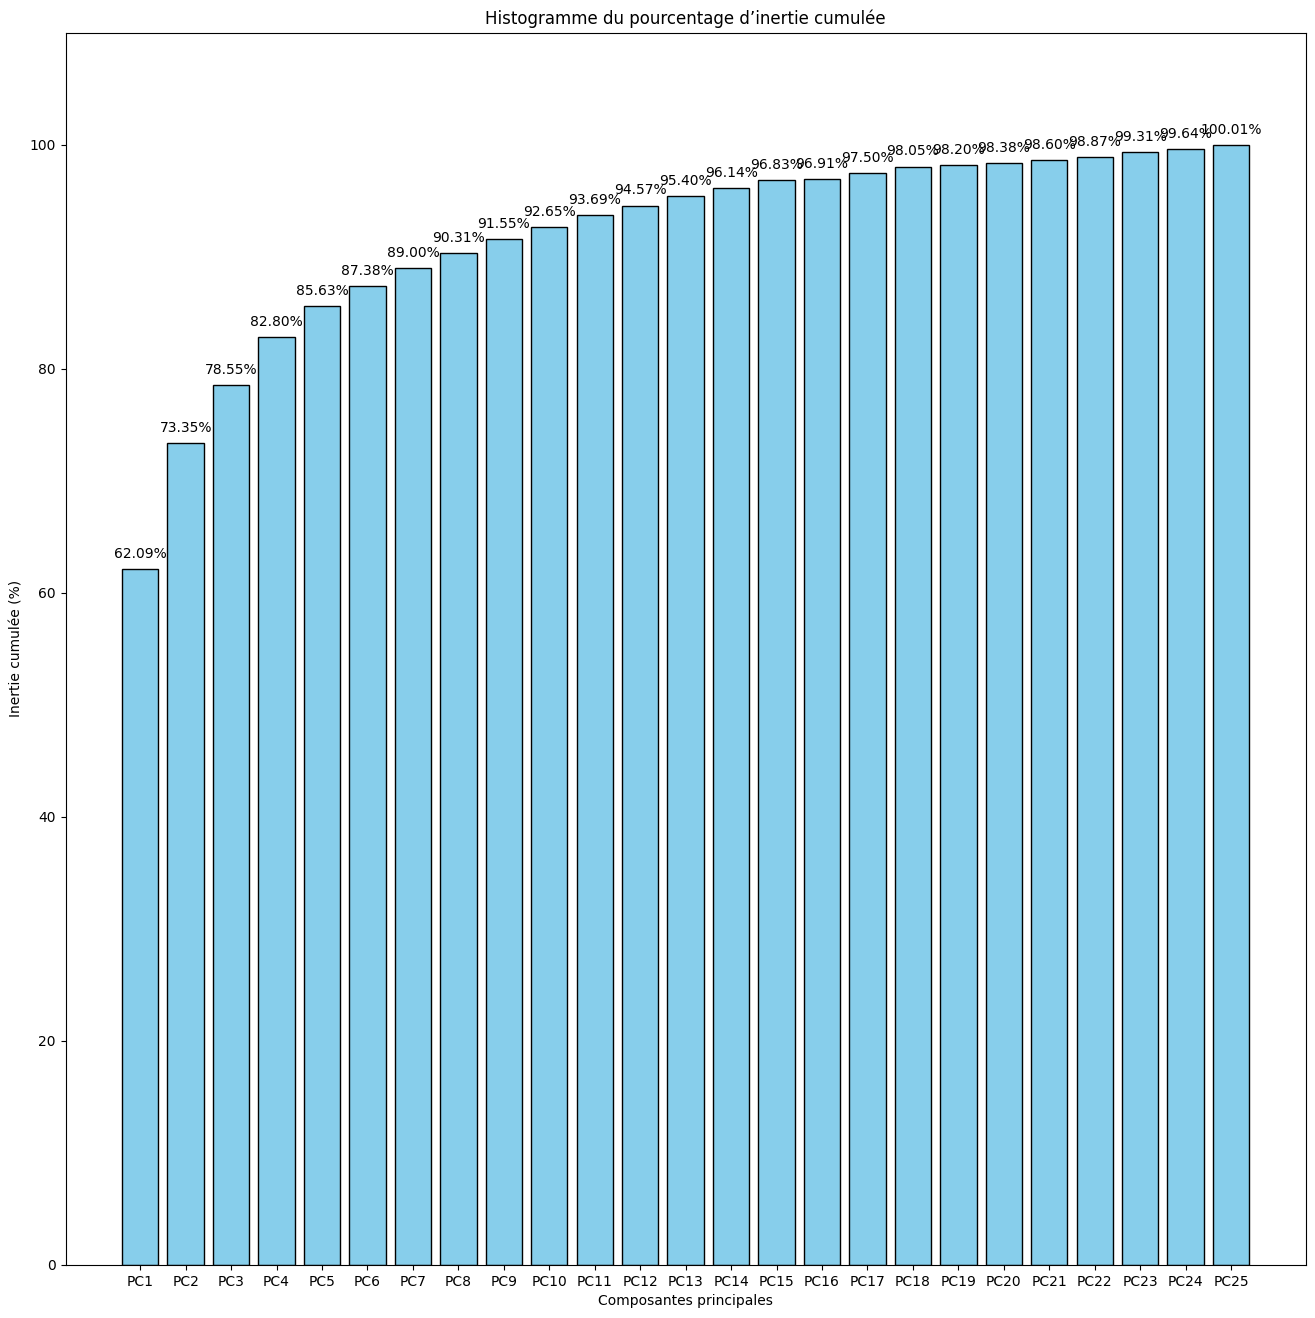

In [124]:
import matplotlib.pyplot as plt

pcs = [f"PC{i+1}" for i in range(len(cumulative_percent))]

plt.figure(figsize=(16,16))

# barres du cumul
plt.bar(pcs, cumulative_percent, color='skyblue', edgecolor='black')

# affichage des valeurs
for i in range(len(cumulative_percent)):
    plt.text(i, cumulative_percent[i] + 1,
             f"{cumulative_percent[i]:.2f}%",
             ha='center')

plt.title("Histogramme du pourcentage d’inertie cumulée")
plt.xlabel("Composantes principales")
plt.ylabel("Inertie cumulée (%)")

plt.ylim(0, 110)

plt.show()

# **5. Principal Components (Projection des données)**


##  Représenter les données sur les axes principaux

* Une fois les valeurs propres et les vecteurs propres calculés, on peut transformer les données initiales.
* L’objectif est de projeter les données sur les nouveaux axes (composantes principales).



## Formule mathématique

$$
F = Z \cdot U
$$


* \(Z\) → données standardisées  
* \(U\) → matrice des vecteurs propres (axes principaux)  
* \(F\) → nouvelles coordonnées (principal components)



In [125]:
eigvals, eigvecs = np.linalg.eig(corr_matrix)

# Trier les valeurs propres
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]

eigvecs = eigvecs[:, idx]

F = np.dot(Z, eigvecs)

F_df = pd.DataFrame(F, index=df.index,
                    columns=[f"PC{i+1}" for i in range(F.shape[1])])

# # affichage propre vecteurs propres
# print("Vecteurs propres:")
# for i, vecteur_propre in enumerate(eigvecs.T):
#     print(f"v{i+1} = {np.round(vecteur_propre, 2)}")

# # tableau final
# F_df.style.set_properties(**{
#     'text-align': 'center',
#     'border': '1px solid black',
#     'padding': '6px'
# }).format("{:.2f}").set_caption("Principal Components (F)")

# **5.1. Contributions des individus (Ctr)**

* La contribution d’un individu indique l’importance de cet individu dans la construction d’un axe factoriel (PC k).



##  Formule

$$
Ctr_{ik} = \frac{F_{ik}^2}{\sum_{i} F_{ik}^2}
$$



* $(F_{ik}) $= coordonnée de l’individu *i* sur l’axe *k*  




##  Interprétation

* Si $(Ctr_{ik})$ est grand → l’individu influence fortement l’axe  
* Si $(Ctr_{ik})$ est petit → l’individu influence peu l’axe  



##  Propriété importante

$
\sum_i Ctr_{ik} = 1 \quad (\text{ou } 100\%)
$

* Tous les individus contribuent à 100% de chaque axe.

In [ ]:
# Contributions des individus (%)
contrib_df = pd.DataFrame(
    (F**2 / np.sum(F**2, axis=0)) * 100,
    columns=[f"PC{i+1}_contribution" for i in range(F.shape[1])]
)



# Arrondi des valeurs
contrib_df = contrib_df.round(2)
# Affichage 
# contrib_df.style.set_properties(**{
#     'text-align': 'center',
#     'border': '1px solid black',
#     'padding': '6px'
# }).format("{:.2f}").set_table_styles([
#     {'selector': 'caption',
#      'props': [
#          ('font-size', '20px'),
#          ('font-weight', 'bold'),
#          ('color', '#2c3e50'),
#          ('text-align', 'center'),
#          ('padding', '10px')
#      ]}
# ]).set_caption("Contributions des individus")

# **5.2. Quality of Representation (cos²)**

* Le cos² (cosine squared) mesure la qualité de représentation d’un individu sur un axe ou sur un plan factoriel.



## Formule

Pour un individu *i* sur un axe *k* :

$$
\cos^2_{ik} = \frac{F_{ik}^2}{\sum_{k} F_{ik}^2}
$$




* $(F_{ik})$ = coordonnée de l’individu *i* sur l’axe *k*  
* le dénominateur = distance totale de l’individu


## Interprétation

* cos² proche de 1 → individu très bien représenté  
* cos² moyen → représentation partielle  
* cos² proche de 0 → mauvaise représentation  

-


In [93]:
# Quality of Representation (cos²)
cos2 = (F**2 / np.sum(F**2, axis=1).reshape(-1,1)).round(2)

# DataFrame avec noms de colonnes
cos2_df = pd.DataFrame(
    cos2,
    index=df.index,
    columns=[f"Qualité_PC{i+1}" for i in range(F.shape[1])]
)

# affichage
# cos2_df.style.set_properties(**{
#     'text-align': 'center',
#     'border': '1px solid black',
#     'padding': '6px'
# }).format("{:.2f}").set_table_styles([
#     {'selector': 'caption',
#      'props': [
#          ('font-size', '20px'),
#          ('font-weight', 'bold'),
#          ('color', '#2c3e50'),
#          ('text-align', 'center'),
#          ('padding', '10px')
#      ]}
# ]).set_caption("Quality of Representation (cos²)")

# **6. Signification de la somme des valeurs propres**


##  Idée principale

En ACP standardisée (sur matrice de corrélation), la somme des valeurs propres correspond à :

$$
\text{Inertie totale} = \text{variance totale du dataset}
$$



##  Résultat important

Pour une matrice de corrélation \(R\)  :

* Chaque variable standardisée a une variance = 1  
* Donc pour \(p\) variables :

$$
\sum_{k=1}^{p} \lambda_k = p = \text{Tr}(R)
$$


$$$$
* $(\text{Tr}(R)) $= trace de la matrice (somme de la diagonale) et la diagonale = 1 (variance standardisée)
Donc :
$$
\text{Tr}(R) = 1 + 1 + \cdots + 1 = p
$$


In [94]:
# Méthode 1 : somme directe
sum1 = np.sum(eigvals)

# Méthode 2 : trace de la matrice
sum2 = np.trace(R)

# Méthode 3 : nombre de variables (ACP standardisée)
sum3 = R.shape[0]

# Affichage
print("Somme des valeurs propres (méthode 1) :", sum1)
print("Trace de R (méthode 2) :", sum2)
print("Nombre de variables (méthode 3) :", sum3)

Somme des valeurs propres (méthode 1) : 25.000000000000025
Trace de R (méthode 2) : 24.993297238658776
Nombre de variables (méthode 3) : 25


# **7. Choix des composantes principales**

Nous choisissons de conserver uniquement les deux premières composantes principales (PC1 et PC2) en nous basant sur deux critères :


## **1. Critère de Kaiser (λ > 1)**

conserver les composantes dont la valeur propre est supérieure à 1.




## **2. Pourcentage cumulé d’inertie**

Ce critère consiste à conserver suffisamment de composantes pour atteindre un pourcentage élevé d’information expliquée (généralement entre 70% et 80%). Cela permet de conservant la majorité de l’information.


In [142]:
print("=== Critère de Kaiser (λ > 1) ===")
for i, val in enumerate(eigvals):
    status = "✓ retenue" if val > 1 else "✗ rejetée"
    print(f"  PC{i+1}: λ = {val:.3f}  {status}")

retained = [i for i, v in enumerate(eigvals) if v > 1]
print(f"\n=== Pourcentage d'inertie cumulée ===")
print(f"  PC1 explique       : {percent_inertia[0]:.2f}%")
print(f"  PC2 explique       : {percent_inertia[1]:.2f}%")
print(f"  Cumul PC1 + PC2    : {cumulative_percent[1]:.2f}%")
print(f"  PC3 explique       : {percent_inertia[2]:.2f}%")
print(f"  Cumul PC1 + PC2 + PC3: {cumulative_percent[2]:.2f}%")
print(f"  PC4 explique       : {percent_inertia[3]:.2f}%")
print(f"  Cumul PC1 + PC2 + PC3 + PC4: {cumulative_percent[3]:.2f}%")

print(f"\n=== Conclusion ===")
print(f"  On retient {len(retained)} composante(s) principale(s): {', '.join([f'PC{i+1}' for i in retained])}")

=== Critère de Kaiser (λ > 1) ===
  PC1: λ = 15.523  ✓ retenue
  PC2: λ = 2.816  ✓ retenue
  PC3: λ = 1.300  ✓ retenue
  PC4: λ = 1.063  ✓ retenue
  PC5: λ = 0.709  ✗ rejetée
  PC6: λ = 0.436  ✗ rejetée
  PC7: λ = 0.405  ✗ rejetée
  PC8: λ = 0.327  ✗ rejetée
  PC9: λ = 0.310  ✗ rejetée
  PC10: λ = 0.275  ✗ rejetée
  PC11: λ = 0.260  ✗ rejetée
  PC12: λ = 0.220  ✗ rejetée
  PC13: λ = 0.208  ✗ rejetée
  PC14: λ = 0.185  ✗ rejetée
  PC15: λ = 0.172  ✗ rejetée
  PC16: λ = 0.149  ✗ rejetée
  PC17: λ = 0.138  ✗ rejetée
  PC18: λ = 0.109  ✗ rejetée
  PC19: λ = 0.093  ✗ rejetée
  PC20: λ = 0.082  ✗ rejetée
  PC21: λ = 0.066  ✗ rejetée
  PC22: λ = 0.055  ✗ rejetée
  PC23: λ = 0.045  ✗ rejetée
  PC24: λ = 0.037  ✗ rejetée
  PC25: λ = 0.019  ✗ rejetée

=== Pourcentage d'inertie cumulée ===
  PC1 explique       : 62.09%
  PC2 explique       : 11.26%
  Cumul PC1 + PC2    : 73.35%
  PC3 explique       : 5.20%
  Cumul PC1 + PC2 + PC3: 78.55%
  PC4 explique       : 4.25%
  Cumul PC1 + PC2 + PC3 + PC4:

# **8. Représentation des individus dans le plan factoriel**



In [127]:
import numpy as np
import pandas as pd

scores = F[:, :4]   # PC1, PC2, PC3 et PC4

scores_df = pd.DataFrame(
    scores,
    index=df.index,
    columns=["PC1_score", "PC2_score", "PC3_score", "PC4_score"]
)

contrib = (F[:, :4]**2 / np.sum(F[:, :4]**2, axis=0)) * 100

contrib_df = pd.DataFrame(
    contrib,
    index=df.index,
    columns=["PC1_contribution", "PC2_contribution", "PC3_contribution", "PC4_contribution"]
).round(2)

cos2 = (F[:, :4]**2 / np.sum(F**2, axis=1).reshape(-1,1))[:, :4]
cos2_df = pd.DataFrame(
    cos2,
    index=df.index,
    columns=["Qualité_PC1", "Qualité_PC2", "Qualité_PC3", "Qualité_PC4"]
).round(2)
final_df = pd.concat([scores_df, contrib_df, cos2_df], axis=1)
final_df.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '6px'
}).format("{:.2f}").set_table_styles([
    {'selector': 'caption',
     'props': [
         ('font-size', '20px'),
         ('font-weight', 'bold'),
         ('color', '#2c3e50'),
         ('text-align', 'center'),
         ('padding', '10px')
     ]}
]).set_caption("ACP des individus (PC1 & PC2)")

,PC1_score,PC2_score,PC3_score,PC4_score,PC1_contribution,PC2_contribution,PC3_contribution,PC4_contribution,Qualité_PC1,Qualité_PC2,Qualité_PC3,Qualité_PC4
S1,-0.40,-2.25,1.17,-0.51,0.00,0.35,0.21,0.05,0.02,0.51,0.14,0.03
S2,2.53,-1.71,0.92,-1.42,0.08,0.20,0.13,0.38,0.38,0.17,0.05,0.12
S3,2.73,-1.16,0.37,-0.60,0.09,0.09,0.02,0.07,0.52,0.09,0.01,0.02
S4,1.73,-1.53,0.75,-2.68,0.04,0.16,0.09,1.33,0.19,0.15,0.04,0.45
S5,3.65,-1.03,1.18,-1.86,0.17,0.07,0.21,0.64,0.63,0.05,0.07,0.16
S6,2.25,-1.92,1.09,0.29,0.06,0.26,0.18,0.02,0.41,0.30,0.10,0.01
S7,6.61,-1.06,1.43,-0.37,0.55,0.08,0.31,0.03,0.86,0.02,0.04,0.00
S8,3.86,-1.47,0.75,-1.37,0.19,0.15,0.08,0.35,0.65,0.09,0.02,0.08
S9,-0.65,-3.01,1.13,-1.17,0.01,0.63,0.19,0.25,0.03,0.57,0.08,0.09
S10,3.88,-0.91,1.56,-0.79,0.19,0.06,0.37,0.12,0.63,0.03,0.10,0.03


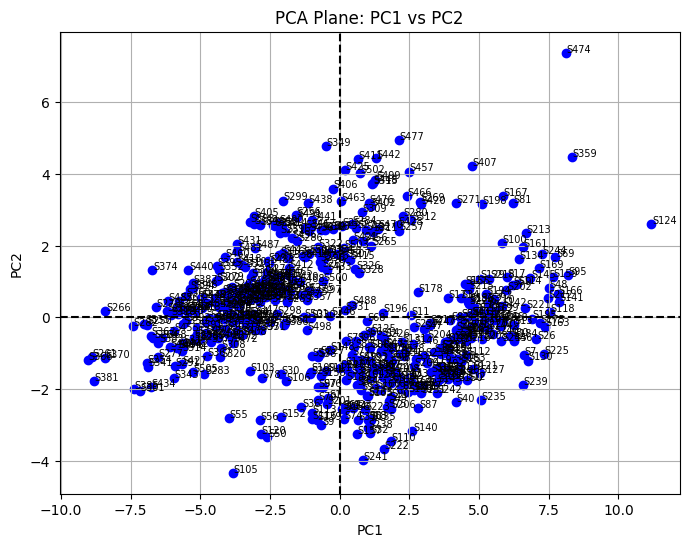

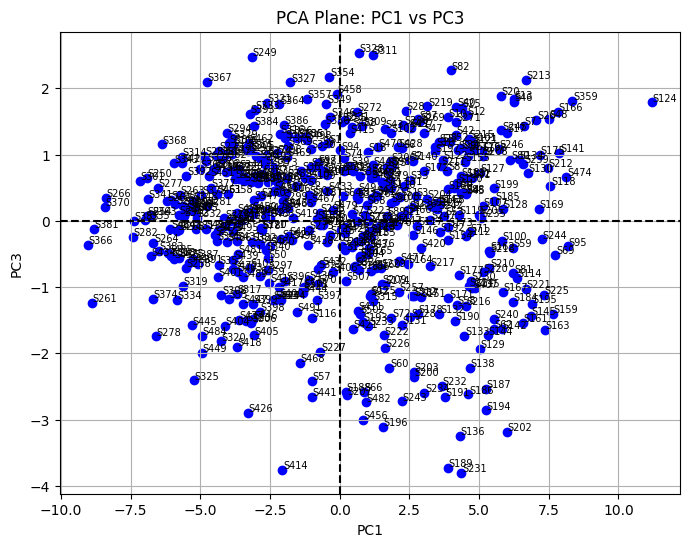

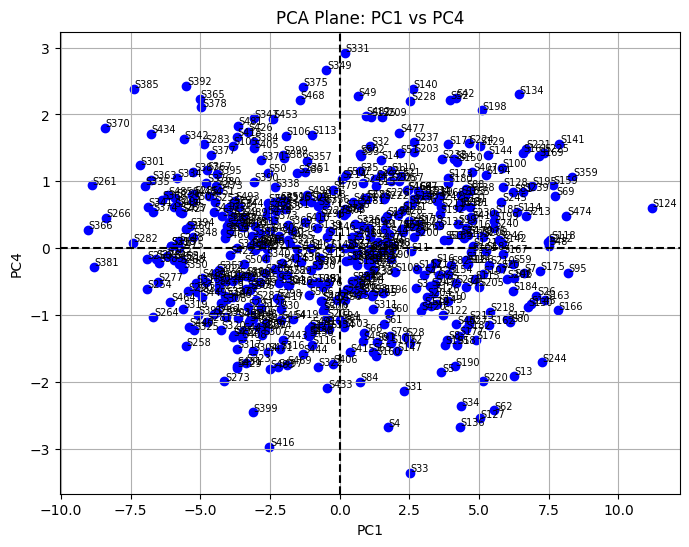

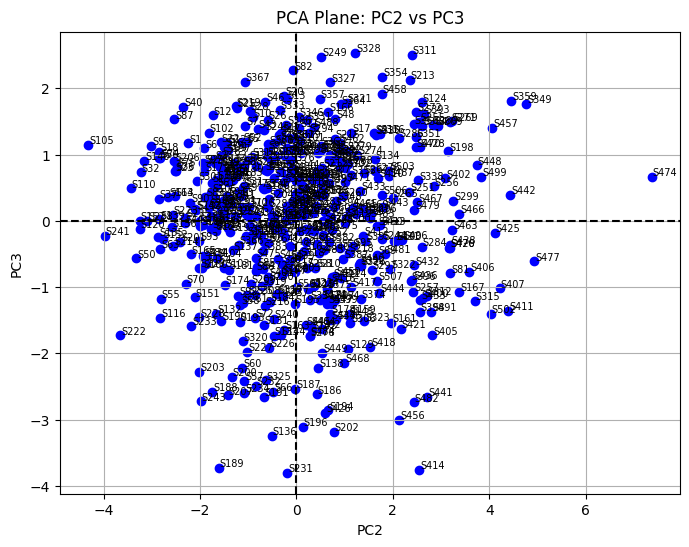

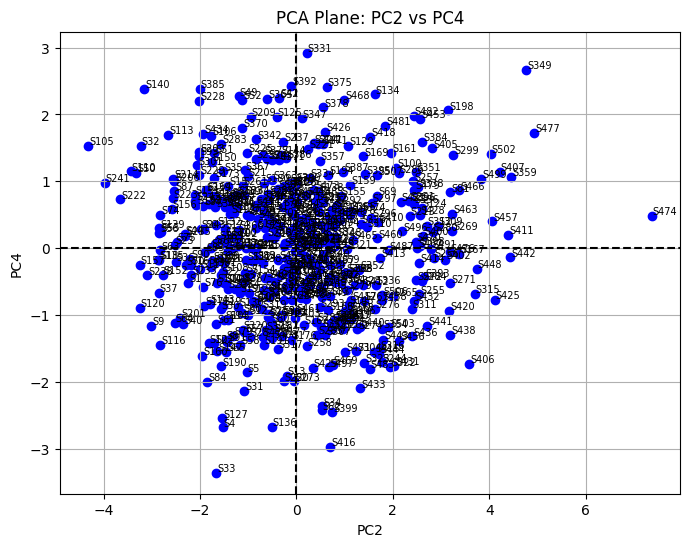

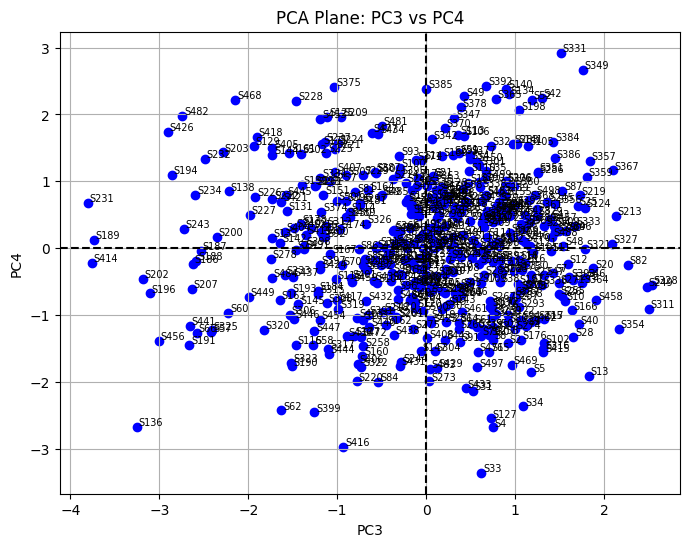

In [130]:
import matplotlib.pyplot as plt

pairs = [
    (0, 1),  # PC1-PC2
    (0, 2),  # PC1-PC3
    (0, 3),  # PC1-PC4
    (1, 2),  # PC2-PC3
    (1, 3),  # PC2-PC4
    (2, 3)   # PC3-PC4
]

for x, y in pairs:
    plt.figure(figsize=(8,6))

    for i in range(F_df.shape[0]):
        plt.scatter(F_df.iloc[i, x], F_df.iloc[i, y], color='blue')
        plt.text(F_df.iloc[i, x]+0.02, F_df.iloc[i, y]+0.02, F_df.index[i], fontsize=7)

    plt.axhline(0, color='black', linestyle='--')
    plt.axvline(0, color='black', linestyle='--')

    plt.xlabel(f"PC{x+1}")
    plt.ylabel(f"PC{y+1}")
    plt.title(f"PCA Plane: PC{x+1} vs PC{y+1}")
    plt.grid(True)
    plt.show()

## **9. Coordonnées des variables**

Les variables sont représentées par leurs corrélations avec les axes :

$$
a_{jk} = \text{Corr}(X_j, PC_k) = \sqrt{\lambda_k} \cdot u_{jk}
$$

où :

* $(u_{jk}) $= composante du vecteur propre  
* $(\lambda_k)$ = valeur propre de l’axe \(k\)

* mesurent l’importance d’une variable dans la construction d’un axe.
* Plus $(|a_{jk}|)$ est grand → plus la variable est liée à la composante principale.

In [132]:
p = len(eigvals)

# matrice des coordonnées des variables
coord = np.zeros((p, p))

for j in range(p):          # variable
    for k in range(p):      # composante
        coord[j, k] = np.sqrt(eigvals[k]) * eigvecs[j, k]

# DataFrame avec titres "Charges PC"
coord_df = pd.DataFrame(
    coord,
    index=df.columns,
    columns=[f"Charges_PC{i+1}" for i in range(p)]
)

# affichage
coord_df.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '6px'
}).format("{:.2f}").set_table_styles([
    {'selector': 'caption',
     'props': [
         ('font-size', '20px'),
         ('font-weight', 'bold'),
         ('color', '#2c3e50'),
         ('text-align', 'center'),
         ('padding', '10px')
     ]}
]).set_caption("Charges des variables (Loadings)")

,Charges_PC1,Charges_PC2,Charges_PC3,Charges_PC4,Charges_PC5,Charges_PC6,Charges_PC7,Charges_PC8,Charges_PC9,Charges_PC10,Charges_PC11,Charges_PC12,Charges_PC13,Charges_PC14,Charges_PC15,Charges_PC16,Charges_PC17,Charges_PC18,Charges_PC19,Charges_PC20,Charges_PC21,Charges_PC22,Charges_PC23,Charges_PC24,Charges_PC25
biacromial_diameter,0.79,-0.34,0.07,-0.18,-0.19,-0.02,0.27,-0.02,-0.01,0.01,0.05,0.05,-0.01,-0.18,-0.21,0.13,-0.07,-0.03,-0.01,0.02,0.04,0.02,0.02,-0.00,0.00
biiliac_diameter,0.48,0.49,-0.18,-0.50,-0.28,0.01,-0.09,0.37,0.05,0.01,-0.06,-0.04,0.03,-0.04,0.00,-0.03,-0.03,0.04,-0.00,-0.03,-0.01,0.00,0.00,-0.00,-0.00
bitrochanteric_diameter,0.68,0.44,-0.05,-0.38,-0.09,0.12,0.19,-0.17,0.09,-0.25,0.07,0.11,-0.02,0.09,0.11,-0.03,-0.00,-0.05,-0.04,0.04,0.01,-0.04,-0.01,0.02,0.00
chest_depth,0.80,0.01,-0.23,0.21,-0.11,-0.25,-0.14,0.01,-0.22,-0.22,0.18,0.05,0.14,-0.10,0.05,-0.01,-0.02,-0.00,0.01,0.02,-0.03,0.02,-0.01,-0.01,-0.01
chest_diameter,0.86,-0.15,-0.03,0.09,-0.15,0.11,0.23,-0.00,0.08,0.18,0.13,-0.13,0.12,-0.01,0.15,-0.05,-0.01,-0.02,0.13,0.03,-0.03,0.02,-0.02,-0.02,-0.00
elbow_diameter,0.88,-0.27,0.00,-0.12,0.05,0.11,-0.12,-0.08,0.02,-0.07,-0.02,-0.03,0.00,0.01,0.10,0.23,0.00,0.17,0.06,-0.06,0.03,-0.03,-0.00,-0.02,-0.00
wrist_diameter,0.84,-0.27,0.02,-0.10,0.16,0.14,-0.09,-0.06,0.04,-0.00,-0.16,0.03,0.31,0.04,-0.09,-0.07,-0.05,0.06,-0.04,0.09,-0.01,0.01,-0.00,0.01,-0.00
knee_diameter,0.82,0.05,0.17,-0.22,0.20,0.24,-0.04,0.04,-0.24,0.13,0.15,0.15,-0.06,-0.07,-0.02,-0.07,0.15,0.04,0.01,0.02,0.01,-0.00,0.01,0.01,-0.01
ankle_diameter,0.81,-0.21,-0.04,-0.25,0.18,0.04,-0.30,-0.06,0.13,0.06,0.23,-0.12,-0.05,0.04,-0.04,0.02,-0.10,-0.12,-0.05,-0.02,-0.00,0.02,-0.01,-0.01,-0.00
shoulder_girth,0.91,-0.20,-0.00,0.19,-0.11,0.06,0.10,0.01,0.01,0.05,-0.01,-0.04,-0.02,-0.03,0.04,0.01,0.04,0.04,-0.19,-0.06,-0.10,-0.03,-0.09,0.01,-0.01


##  **9.1. Contributions des variables (Ctr)**

La contribution indique dans quelle mesure une variable participe à la construction d’une composante principale.

$$
Ctr_{jk} = \frac{a_{jk}^2}{\sum_j a_{jk}^2}
$$

où :

* $(a_{jk})$ = corrélation entre la variable \(j\) et l’axe \(k\)


##  Propriété

$$
\sum_j Ctr_{jk} = 1 \quad (\text{ou } 100\%)
$$

* Toutes les variables contribuent à 100% pour chaque axe.

## **9.2. Qualité de représentation des variables (cos²)**

La qualité de représentation (cos²) mesure à quel point une variable est bien représentée par une composante principale.

Comme les variables sont standardisées (variance = 1), on a :

$$
\cos^2_{jk} = \frac{a_{jk}^2}{\sum_k a_{jk}^2}
$$


* $(a_{jk}) $= corrélation entre la variable \(j\) et l’axe \(k\)
* cos² proche de 1 → la variable est très bien représentée par l’axe  
* cos² proche de 0 → la variable est mal représentée  


In [135]:
import numpy as np
import pandas as pd

# ===== Charges  =====
loadings = coord[:, :4]

loadings_df = pd.DataFrame(
    loadings,
    index=df.columns,
    columns=["PC1_loading", "PC2_loading", "PC3_loading", "PC4_loading"]
)

# ===== Contributions des variables =====
contrib_var = (coord[:, :4]**2 / np.sum(coord[:, :4]**2, axis=0))

contrib_var_df = pd.DataFrame(
    contrib_var,
    index=df.columns,
    columns=["PC1_contribution", "PC2_contribution", "PC3_contribution", "PC4_contribution"]
).round(2)

# ===== Cos² des variables =====
cos2_var = coord[:, :4]**2 / np.sum(coord**2, axis=1).reshape(-1,1)

cos2_var_df = pd.DataFrame(
    cos2_var,
    index=df.columns,
    columns=["Qualité_PC1", "Qualité_PC2", "Qualité_PC3", "Qualité_PC4"]
).round(2)


final_var_df = pd.concat([loadings_df, contrib_var_df, cos2_var_df], axis=1)

# ===== Affichage
final_var_df.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '6px'
}).format("{:.2f}").set_table_styles([
    {'selector': 'caption',
     'props': [
         ('font-size', '20px'),
         ('font-weight', 'bold'),
         ('color', '#2c3e50'),
         ('text-align', 'center'),
         ('padding', '10px')
     ]}
]).set_caption(" variables (PC1 & PC2)")

,PC1_loading,PC2_loading,PC3_loading,PC4_loading,PC1_contribution,PC2_contribution,PC3_contribution,PC4_contribution,Qualité_PC1,Qualité_PC2,Qualité_PC3,Qualité_PC4
biacromial_diameter,0.79,-0.34,0.07,-0.18,0.04,0.04,0.00,0.03,0.63,0.12,0.00,0.03
biiliac_diameter,0.48,0.49,-0.18,-0.50,0.01,0.09,0.02,0.24,0.23,0.24,0.03,0.25
bitrochanteric_diameter,0.68,0.44,-0.05,-0.38,0.03,0.07,0.00,0.13,0.46,0.19,0.00,0.14
chest_depth,0.80,0.01,-0.23,0.21,0.04,0.00,0.04,0.04,0.64,0.00,0.05,0.04
chest_diameter,0.86,-0.15,-0.03,0.09,0.05,0.01,0.00,0.01,0.75,0.02,0.00,0.01
elbow_diameter,0.88,-0.27,0.00,-0.12,0.05,0.03,0.00,0.01,0.77,0.07,0.00,0.02
wrist_diameter,0.84,-0.27,0.02,-0.10,0.05,0.03,0.00,0.01,0.71,0.07,0.00,0.01
knee_diameter,0.82,0.05,0.17,-0.22,0.04,0.00,0.02,0.04,0.66,0.00,0.03,0.05
ankle_diameter,0.81,-0.21,-0.04,-0.25,0.04,0.02,0.00,0.06,0.65,0.04,0.00,0.06
shoulder_girth,0.91,-0.20,-0.00,0.19,0.05,0.01,0.00,0.03,0.83,0.04,0.00,0.03


# **10. Cercle de corrélation (correlation circle).**

## Définition

Le cercle de corrélation est une représentation graphique des variables dans le plan factoriel (PC1, PC2).

Chaque variable est représentée par un point de coordonnées :

$$
(a_{j1}, a_{j2})
$$

* $(a_{j1})$= corrélation entre la variable \(j\) et PC1  
* $(a_{j2})$ = corrélation entre la variable \(j\) et PC2  


## Propriété du cercle

Les variables sont projetées dans un cercle de rayon 1 :

$$
a_{j1}^2 + a_{j2}^2 \leq 1
$$
* Si la somme ≈ 1 → la variable est bien représentée sur le plan (PC1, PC2)



##  Interprétation

### Longueur du vecteur
* proche du cercle → variable bien représentée  
* proche du centre → variable mal représentée  

### Angle entre variables

* angle petit → variables fortement corrélées positivement  
* angle ≈ 180° → corrélation négative  
* angle ≈ 90° → variables indépendantes  


## Objectif

Le cercle de corrélation permet de :

* comprendre les relations entre variables  
* identifier des groupes de variables similaires  
* interpréter les axes principaux (PC1, PC2)

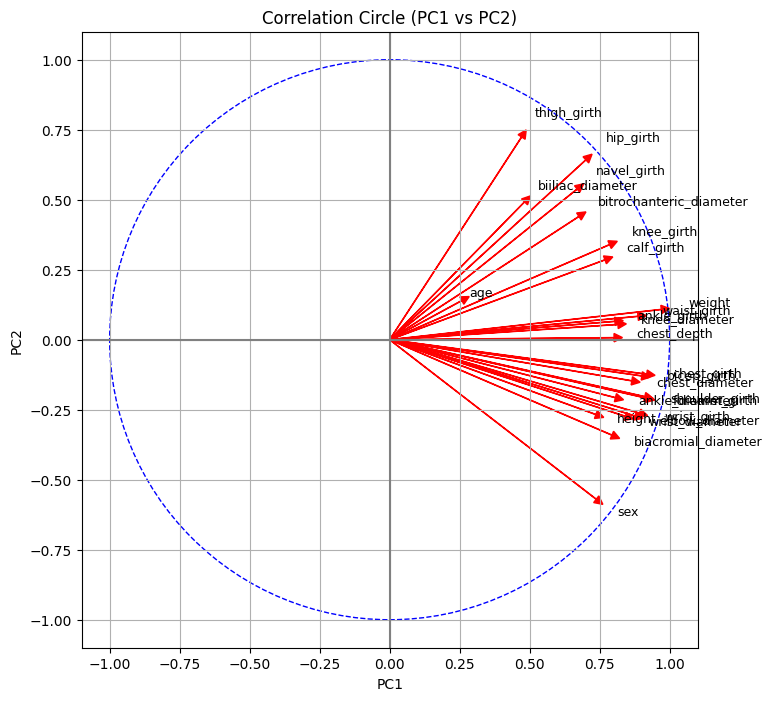

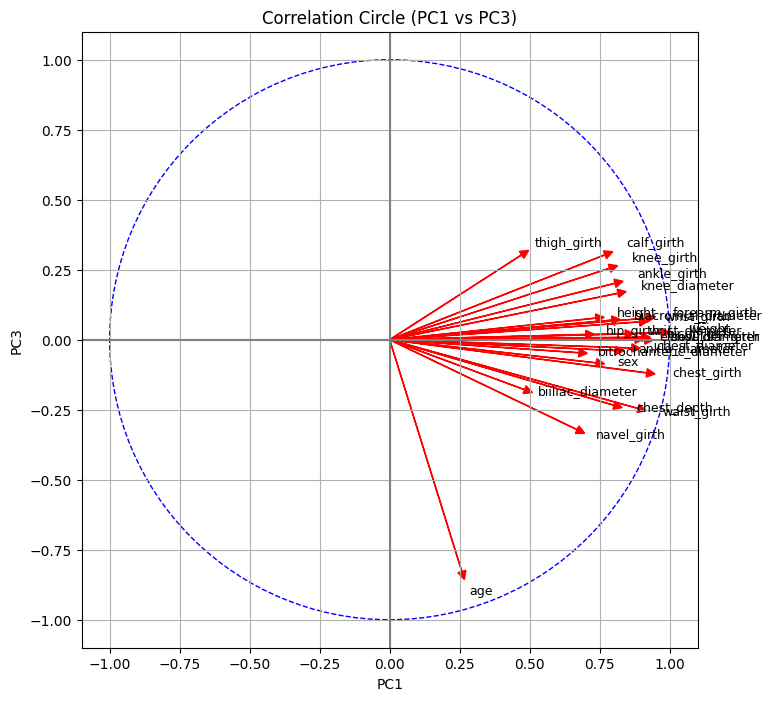

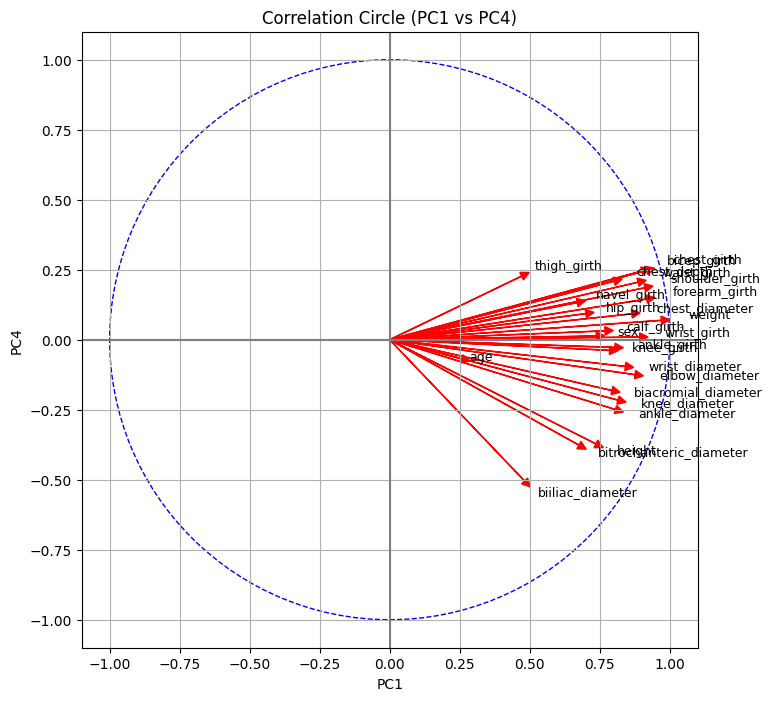

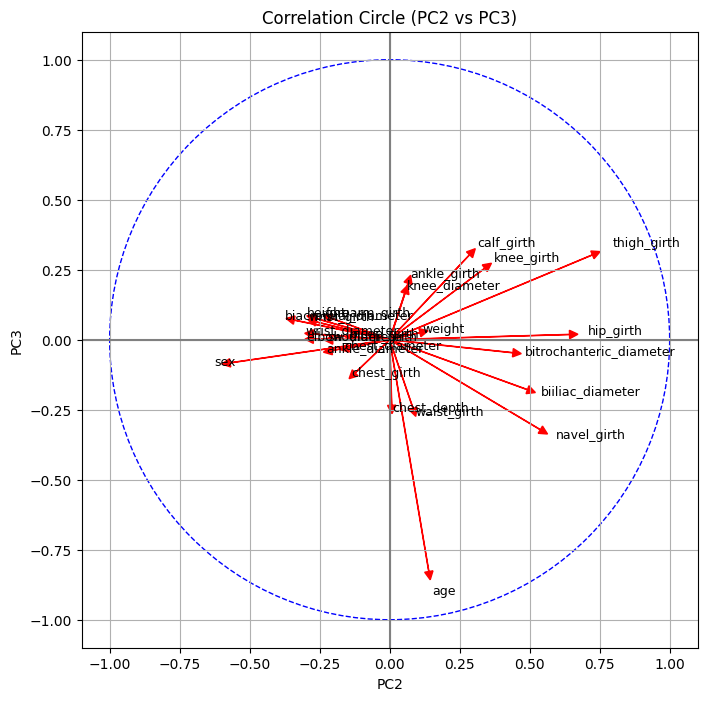

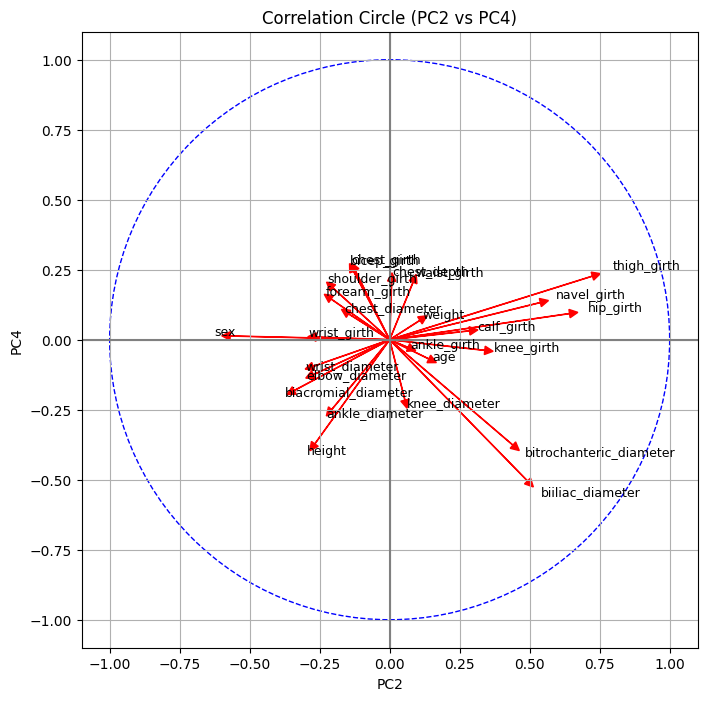

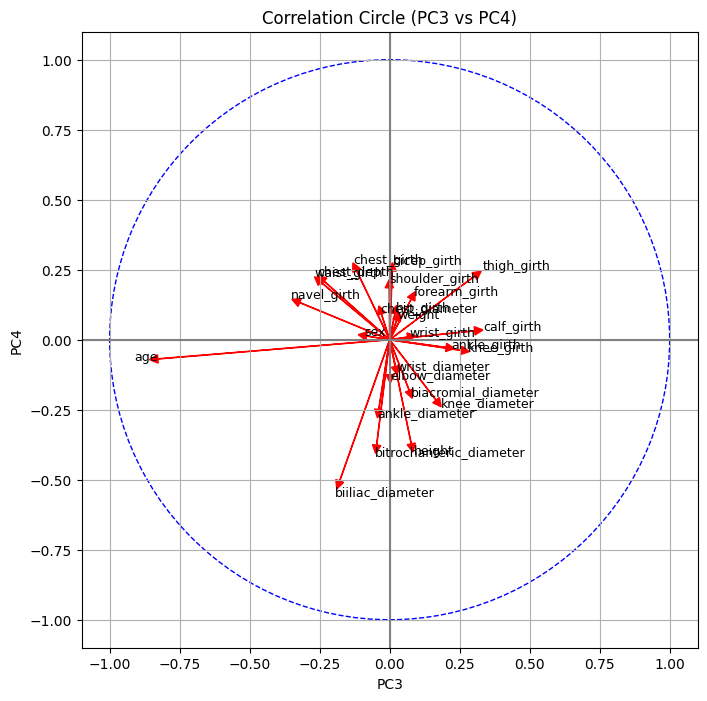

In [141]:
import matplotlib.pyplot as plt

pairs = [(0,1), (0,2), (0,3), (1,2), (1,3), (2,3)]  # PC1-PC2, PC1-PC3, PC1-PC4, PC2-PC3, PC2-PC4, PC3-PC4

for pcx, pcy in pairs:
    fig, ax = plt.subplots(figsize=(8,8))

    # unit circle
    circle = plt.Circle((0, 0), 1, fill=False, linestyle='--', color='blue')
    ax.add_artist(circle)

    ax.axhline(0, color='grey')
    ax.axvline(0, color='grey')

    # variables arrows
    for i in range(coord_df.shape[0]):
        x = coord_df.iloc[i, pcx]
        y = coord_df.iloc[i, pcy]

        ax.arrow(0, 0, x, y, head_width=0.03, head_length=0.03, fc='red', ec='red')
        ax.text(x*1.1, y*1.1, coord_df.index[i], fontsize=9)

    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)

    ax.set_xlabel(f"PC{pcx+1}")
    ax.set_ylabel(f"PC{pcy+1}")
    ax.set_title(f"Correlation Circle (PC{pcx+1} vs PC{pcy+1})")

    ax.set_aspect('equal')
    ax.grid(True)

    plt.show()

## **11. Analyse des corrélations entre les sous-tests**



In [139]:
import numpy as np

strong_corr = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .loc[lambda x: x.abs() > 0.8]
    .sort_values(ascending=False)
)

print("Les subtests fortement corrélés (|r| > 0.8) :")
print(strong_corr)

Les subtests fortement corrélés (|r| > 0.8) :
bicep_girth     forearm_girth     0.942376
shoulder_girth  chest_girth       0.927192
chest_girth     bicep_girth       0.908185
forearm_girth   wrist_girth       0.904709
waist_girth     weight            0.903991
chest_girth     weight            0.898959
shoulder_girth  bicep_girth       0.895188
                forearm_girth     0.894984
chest_girth     forearm_girth     0.887591
                waist_girth       0.883799
shoulder_girth  weight            0.878834
chest_diameter  shoulder_girth    0.870648
                chest_girth       0.870306
forearm_girth   weight            0.869553
bicep_girth     weight            0.866672
wrist_diameter  wrist_girth       0.862553
elbow_diameter  forearm_girth     0.858206
bicep_girth     wrist_girth       0.847944
elbow_diameter  wrist_girth       0.845756
shoulder_girth  wrist_girth       0.840709
elbow_diameter  wrist_diameter    0.839931
chest_diameter  weight            0.831465
hip_girt



### **12. Justification des variables bien représentées sur le plan (PC1, PC2, PC3, PC4)**

L'analyse de la qualité de représentation des variables s'appuie sur le **cosinus carré ($\cos^2$)** et la proximité des variables avec le bord du **cercle des corrélations**.

1. **Sur PC1 (Axe de la "Taille Globale / Corpulence")**
   * **Variables :** `weight`, `waist_girth`, `chest_girth`, `hip_girth`.
   * **Justification :** Ces variables présentent des corrélations très fortes avec PC1 ($> 0.8$). Elles se situent très proches du bord du cercle sur l'axe horizontal, représentant l'aspect volumétrique des individus.

2. **Sur PC2 (Axe de la "Stature / Structure Osseuse")**
   * **Variables :** `height`, `shoulder_breadth`.
   * **Justification :** Ces variables ont une coordonnée élevée sur l'axe vertical. Elles permettent de distinguer la taille (hauteur) de la corpulence (volume) déjà captée par PC1.

3. **Sur PC3 et PC4 (Axes des "Détails Morphologiques")**
   * **Variables :** `age`, `wrist_diameter`, `knee_diameter`.
   * **Justification :** Souvent mal représentées sur le premier plan (PC1-PC2), leur $\cos^2$ augmente significativement sur PC3 ou PC4. Elles capturent des nuances spécifiques (finesse des articulations, âge) indépendantes de la corpulence générale.

**Conclusion :**
Une variable est jugée bien représentée sur le plan (PC1 à PC4) si sa **communalité** (somme des $\cos^2$ sur ces quatre axes) est proche de 1. Dans notre étude, la majorité des variables anthropométriques sont captées dès les deux premiers axes, tandis que les mesures plus spécifiques nécessitent les axes 3 et 4 pour une représentation satisfaisante.